In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.datasets import fashion_mnist
from keras.models import Sequential, Model
from keras.layers import Conv2D, AveragePooling2D, Flatten, Dense, Input, concatenate, BatchNormalization, Activation, Dropout, MaxPool2D
from keras.utils import to_categorical
from sklearn.manifold import TSNE

In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

x_train = x_train.reshape(-1, 28, 28, 1).astype("float32") / 255.0
x_test = x_test.reshape(-1, 28, 28, 1).astype("float32") / 255.0
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

In [3]:
# Define LeNet-5 model
lenet_model = Sequential([
    Conv2D(6, kernel_size=5, activation='relu', input_shape=(28, 28, 1), padding='same'),
    AveragePooling2D(pool_size=(2, 2)),
    Conv2D(16, kernel_size=5, activation='relu'),
    AveragePooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(120, activation='relu'),
    Dense(84, activation='relu'),
    Dense(10, activation='softmax')
])

/Users/davemag9/Desktop/Computer vision/venv/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [4]:
lenet_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
lenet_model.fit(x_train, y_train_cat, batch_size=128, epochs=10, validation_data=(x_test, y_test_cat))

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.6681 - loss: 0.9541 - val_accuracy: 0.8129 - val_loss: 0.5202
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.8241 - loss: 0.4849 - val_accuracy: 0.8373 - val_loss: 0.4505
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.8477 - loss: 0.4222 - val_accuracy: 0.8468 - val_loss: 0.4190
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.8634 - loss: 0.3765 - val_accuracy: 0.8634 - val_loss: 0.3847
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.8718 - loss: 0.3551 - val_accuracy: 0.8641 - val_loss: 0.3771
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.8768 - loss: 0.3360 - val_accuracy: 0.8749 - val_loss: 0.3563
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.8843 - loss: 0.3148 - val_accuracy: 0.8725 - val_loss: 0.3445
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.8915 - loss: 0.2987 - v

In [5]:
test_loss, test_accuracy = lenet_model.evaluate(x_test, y_test_cat)
print(f"Test Accuracy: {test_accuracy:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8814 - loss: 0.3475
Test Accuracy: 0.8811


In [6]:
train_groups = [x_train[y_train == i] for i in np.unique(y_train)]
test_groups = [x_test[y_test == i] for i in np.unique(y_test)]

In [7]:
def gen_random_batch(in_groups, batch_halfsize=8):
    out_img_a, out_img_b, out_score = [], [], []
    all_groups = list(range(len(in_groups)))
    for match_group in [True, False]:
        group_idx = np.random.choice(all_groups, size=batch_halfsize)
        if match_group:
            b_group_idx = group_idx
            out_score += [1] * batch_halfsize
        else:
            b_group_idx = [np.random.choice([i for i in all_groups if i != c_idx]) for c_idx in group_idx]
            out_score += [0] * batch_halfsize
        out_img_a += [in_groups[c_idx][np.random.choice(len(in_groups[c_idx]))] for c_idx in group_idx]
        out_img_b += [in_groups[c_idx][np.random.choice(len(in_groups[c_idx]))] for c_idx in b_group_idx]
    return np.stack(out_img_a, 0), np.stack(out_img_b, 0), np.stack(out_score, 0)

img_in = Input(shape=(28, 28, 1), name='FeatureNet_ImageInput')
n_layer = img_in

In [8]:
for i in range(2):
    n_layer = Conv2D(8 * 2**i, kernel_size=(3, 3), activation='linear')(n_layer)
    n_layer = BatchNormalization()(n_layer)
    n_layer = Activation('relu')(n_layer)
    n_layer = Conv2D(16 * 2**i, kernel_size=(3, 3), activation='linear')(n_layer)
    n_layer = BatchNormalization()(n_layer)
    n_layer = Activation('relu')(n_layer)
    n_layer = MaxPool2D((2, 2))(n_layer)

n_layer = Flatten()(n_layer)
n_layer = Dense(32, activation='relu')(n_layer)
n_layer = Dropout(0.5)(n_layer)
n_layer = BatchNormalization()(n_layer)
n_layer = Activation('relu')(n_layer)
feature_model = Model(inputs=img_in, outputs=n_layer, name='FeatureGenerationModel')

In [9]:
img_a_in = Input(shape=(28, 28, 1), name='ImageA_Input')
img_b_in = Input(shape=(28, 28, 1), name='ImageB_Input')
img_a_feat = feature_model(img_a_in)
img_b_feat = feature_model(img_b_in)

combined_features = concatenate([img_a_feat, img_b_feat], name='merge_features')
combined_features = Dense(16, activation='relu')(combined_features)
combined_features = BatchNormalization()(combined_features)
combined_features = Dense(4, activation='relu')(combined_features)
combined_features = BatchNormalization()(combined_features)
combined_features = Dense(1, activation='sigmoid')(combined_features)

similarity_model = Model(inputs=[img_a_in, img_b_in], outputs=combined_features, name='Similarity_Model')
similarity_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['mae'])

In [10]:
def siam_gen(in_groups, batch_size=32):
    def generator():
        while True:
            a, b, sim = gen_random_batch(in_groups, batch_size // 2)
            yield (a.astype(np.float32), b.astype(np.float32)), sim.astype(np.float32)
    return tf.data.Dataset.from_generator(generator,
        output_signature=((
            tf.TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32),
            tf.TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32)
        ), tf.TensorSpec(shape=(None,), dtype=tf.float32)))

In [11]:
train_ds = siam_gen(train_groups, batch_size=32)
valid_a, valid_b, valid_sim = gen_random_batch(test_groups, 1024)
loss_history = similarity_model.fit(train_ds, steps_per_epoch=500, validation_data=([valid_a, valid_b], valid_sim), epochs=10, verbose=True)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - loss: 0.7188 - mae: 0.4894 - val_loss: 0.5738 - val_mae: 0.4236
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - loss: 0.5836 - mae: 0.4207 - val_loss: 0.4792 - val_mae: 0.3507
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - loss: 0.4893 - mae: 0.3440 - val_loss: 0.4110 - val_mae: 0.2923
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - loss: 0.4488 - mae: 0.3058 - val_loss: 0.3845 - val_mae: 0.2615
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - loss: 0.4398 - mae: 0.2892 - val_loss: 0.3763 - val_mae: 0.2600
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - loss: 0.4348 - mae: 0.2834 - val_loss: 0.3595 - val_mae: 0.2478
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - loss: 0.4191 - mae: 0.2748 - val_loss: 0.3573 - val_mae: 0.2480
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - loss: 0.4112 - mae: 0.2635 - val_loss: 0.3487 - val_mae: 0.2391
Epoch 9/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 

In [12]:
x_test_features = feature_model.predict(x_test, batch_size=128, verbose=True)
tsne = TSNE(n_components=2, init='pca', random_state=101, method='barnes_hut', n_iter=500, verbose=1)
tsne_features = tsne.fit_transform(x_test_features.reshape(len(x_test_features), -1))

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 10000 samples in 0.001s...


/Users/davemag9/Desktop/Computer vision/venv/lib/python3.11/site-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


[t-SNE] Computed neighbors for 10000 samples in 0.195s...
[t-SNE] Computed conditional probabilities for sample 1000 / 10000
[t-SNE] Computed conditional probabilities for sample 2000 / 10000
[t-SNE] Computed conditional probabilities for sample 3000 / 10000
[t-SNE] Computed conditional probabilities for sample 4000 / 10000
[t-SNE] Computed conditional probabilities for sample 5000 / 10000
[t-SNE] Computed conditional probabilities for sample 6000 / 10000
[t-SNE] Computed conditional probabilities for sample 7000 / 10000
[t-SNE] Computed conditional probabilities for sample 8000 / 10000
[t-SNE] Computed conditional probabilities for sample 9000 / 10000
[t-SNE] Computed conditional probabilities for sample 10000 / 10000
[t-SNE] Mean sigma: 0.121675
[t-SNE] KL divergence after 250 iterations with early exaggeration: 73.502075
[t-SNE] KL divergence after 500 iterations: 1.507339


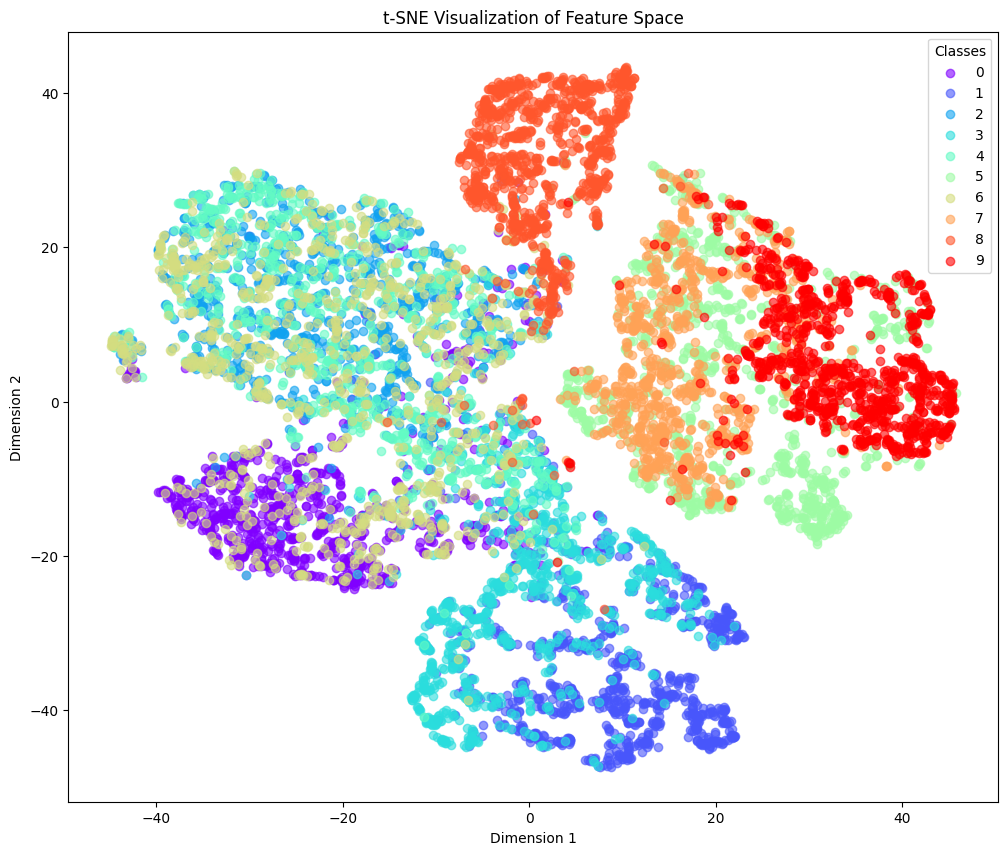

In [13]:
colors = plt.cm.rainbow(np.linspace(0, 1, 10))
plt.figure(figsize=(12, 10))
for i, color in enumerate(colors):
    idx = y_test == i
    plt.scatter(tsne_features[idx, 0], tsne_features[idx, 1], color=color, label=str(i), alpha=0.6)
plt.legend(title="Classes")
plt.title("t-SNE Visualization of Feature Space")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


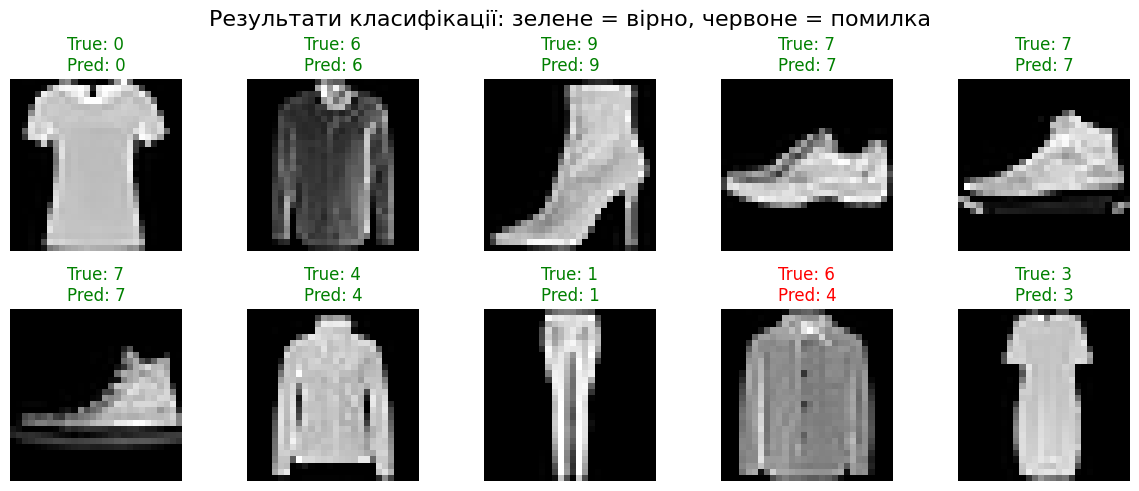

In [15]:
import random
pred_probs = lenet_model.predict(x_test)
pred_labels = pred_probs.argmax(axis=1)
n = 10
indices = random.sample(range(len(x_test)), n)
plt.figure(figsize=(12, 12))
for i, idx in enumerate(indices):
  plt.subplot(5, 5, i + 1)
  plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')
  plt.axis('off')
  true_label = y_test[idx]
  pred_label = pred_labels[idx]
  color = 'green' if true_label == pred_label else 'red'
  plt.title(f'True: {true_label}\nPred: {pred_label}', color=color)
plt.suptitle("Результати класифікації: зелене = вірно, червоне = помилка",
fontsize=16)
plt.tight_layout()
plt.show()